# Análise Comparativa de Arquiteturas Neuronais na Deteção de Sopros Cardíacos

### Aprendizagem Computacional II — CC3043

**Elementos do grupo:**
- Nome: Ana Alves — N.º mecanográfico: `[Número]`
- Nome: Lara Queiroga — N.º mecanográfico: `[Número]`
- Nome: `[Nome do elemento 3]` — N.º mecanográfico: `[Número]`

---

## 1. Introdução

A auscultação cardíaca permite identificar sons associados ao funcionamento do coração, podendo revelar a presença de sopros cardíacos. A análise automática de gravações de áudio constitui, por isso, uma possível abordagem de apoio à identificação destes sinais.

Neste trabalho será utilizado o conjunto de dados **CirCor DigiScope**, que contém gravações de sons cardíacos obtidas em diferentes locais de auscultação, acompanhadas de informação clínica e de anotações relativas aos pacientes.

O objetivo é desenvolver e comparar modelos de redes neuronais capazes de classificar os pacientes em três categorias: `Present`, `Absent` e `Unknown`, correspondentes à presença, ausência ou incerteza relativamente à existência de um sopro cardíaco.

Inicialmente, serão consideradas três arquiteturas — *Multilayer Perceptron* (MLP), *Convolutional Neural Network* (CNN) e *Recurrent Neural Network* (RNN). O objetivo é analisar as suas características e selecionar duas abordagens para implementação, tendo em conta a natureza dos dados, a complexidade dos modelos e a possibilidade de comparar diferentes representações do áudio.

---

## 2. Decisões iniciais

### 2.1. Seleção das arquiteturas

Os dois modelos que decidimos implementar foram os seguintes:
- **RNN — excluída:** apesar de ser adequada à modelação de sequências temporais, a sua utilização não é prioritária neste problema. As CNN permitem explorar padrões acústicos locais e estruturas relevantes dos sons cardíacos através de convoluções.
- **MLP — selecionada:** será utilizada como abordagem de referência, recebendo características acústicas extraídas previamente das gravações.
- **CNN — selecionada:** será utilizada para aprender padrões diretamente a partir de uma representação tempo-frequência do áudio.

Esta seleção permite comparar duas estratégias de representação dos dados, sem implementar modelos em excesso.

### 2.2. Comparação das representações do áudio

A comparação entre a MLP e a CNN pretende estudar se é mais vantajoso fornecer ao modelo características acústicas previamente calculadas ou uma representação mais completa do sinal.

| Aspeto | MLP | CNN 2D |
|---|---|---|
| Entrada | Vetor de características acústicas | Espectrograma Mel |
| Pré-processamento | Extração de características | Transformação do áudio em espectrograma |
| Aprendizagem | Relações entre características calculadas | Padrões locais no tempo e na frequência |
| Vantagem principal | Representação compacta e interpretável | Aprendizagem automática de padrões tempo-frequência |

Para a MLP poderão ser extraídas características como a energia do sinal, o centróide espectral e os coeficientes MFCC (*Mel-Frequency Cepstral Coefficients*), recorrendo a estatísticas que resumam a sua distribuição ao longo do tempo.

Na CNN, cada janela de áudio (segmento de comprimento fixo de uma gravação) será transformada num **espectrograma Mel**, que representa a evolução da energia nas diferentes bandas de frequência ao longo do tempo. Esta representação preserva informação temporal e espectral que a rede poderá utilizar para aprender padrões relevantes para a classificação.

### 2.3. Escolha da CNN 2D em vez da CNN 1D

As CNN 1D processam diretamente a sequência de amplitudes do áudio, aplicando convoluções ao longo do tempo. Embora esta abordagem permita aprender a partir da forma de onda original, pode exigir que a rede aprenda representações acústicas úteis a partir de um sinal de elevada dimensionalidade.

As CNN 2D, por sua vez, processam espectrogramas, aplicando convoluções nas dimensões temporal e frequencial. Esta representação torna explícita a distribuição da energia pelas frequências e a sua evolução ao longo do tempo.

Assim, opta-se pela **CNN 2D** por permitir explorar uma representação tempo-frequência adequada à análise de sinais acústicos e compará-la com a abordagem baseada em características manuais utilizada pela MLP.

Esta decisão não pressupõe que a CNN 2D seja necessariamente superior à CNN 1D; representa uma escolha metodológica para o estudo proposto.

### 2.4. Modelos finais

Os modelos a implementar serão, portanto:

1. **MLP:** recebe características acústicas extraídas das gravações.
2. **CNN 2D:** recebe espectrogramas Mel derivados das mesmas gravações.

A comparação permitirá avaliar o impacto da representação dos dados no desempenho da classificação.

---

## 3. Estratégia de avaliação

A avaliação deverá considerar as particularidades do conjunto de dados e o objetivo de classificar pacientes, em vez de apenas gravações individuais.

Serão tidos em conta os seguintes aspetos:

- **Separação dos dados por paciente:** todas as gravações do mesmo paciente deverão pertencer à mesma partição — treino, validação ou teste — para evitar fuga de informação.
- **Desequilíbrio entre classes:** serão consideradas estratégias como a utilização de pesos por classe durante o treino.
- **Métricas de avaliação:** a métrica principal é a *weighted accuracy* (WA_murmur) do enunciado, com pesos 5/3/1 para `Present`/`Unknown`/`Absent`, calculada ao nível do paciente, juntamente com a matriz de confusão. Como métricas adicionais: *macro-F1*, *recall* por classe e *balanced accuracy*.
- **Classificação ao nível do paciente:** caso sejam produzidas previsões para várias gravações do mesmo paciente, será definida uma estratégia para as combinar numa previsão final.
- **Classe `Unknown`:** será analisada com cuidado, dado que pode representar incerteza na anotação e não necessariamente um padrão acústico distinto.

Os dois modelos deverão ser avaliados com divisões de dados e critérios de avaliação consistentes, permitindo uma comparação tão justa quanto possível.

---

## 4. Organização do trabalho

O trabalho será desenvolvido pelas seguintes etapas:

1. Exploração do conjunto de dados e análise da distribuição das classes.
2. Pré-processamento das gravações de áudio.
3. Extração de características acústicas para a MLP.
4. Geração de espectrogramas Mel para a CNN 2D.
5. Implementação e treino dos dois modelos.
6. Avaliação, comparação dos resultados e análise das limitações.

No final, pretende-se determinar qual das duas abordagens apresenta melhores resultados neste conjunto de dados e discutir a influência da representação do áudio na deteção de sopros cardíacos.

---

## 5. Imports e configuração

Bibliotecas usadas ao longo do notebook e localização do dataset.

> O dataset deve estar na mesma pasta do notebook (a pasta descarregada do PhysioNet, com `training_data.csv` e a pasta `training_data/`). O código procura o ficheiro `training_data.csv` automaticamente.

In [1]:
import os, glob, pickle
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# --- localizar o dataset (basta estar na mesma pasta do notebook) ---
_found = glob.glob("**/training_data.csv", recursive=True)
assert _found, "training_data.csv não encontrado: colocar a pasta do dataset junto ao notebook."
CSV = _found[0]
ROOT = os.path.dirname(CSV)
AUDIO_DIR = os.path.join(ROOT, "training_data")
print("Dataset em:", ROOT)

SEED = 42
CLASSES = ["Present", "Unknown", "Absent"]

Dataset em: the-circor-digiscope-phonocardiogram-dataset-1.0.3


---

## 6. Exploração dos dados

Antes de definir o pré-processamento, é necessário perceber o que existe no dataset. 
- Quantos pacientes há em cada classe (`Present`, `Unknown`, `Absent`)? O desequilíbrio é grande?
- Quantas gravações tem cada paciente e quais as suas durações?
- Em que focos de auscultação (AV, PV, TV, MV) existem gravações, e como se distribuem por classe?

In [2]:
# Tabela por paciente (1 linha = 1 paciente; é aqui que está a label)
meta = pd.read_csv(CSV).rename(columns={"Patient ID": "patient_id"})
pat = meta[["patient_id", "Murmur", "Murmur locations"]].copy()
print(pat["Murmur"].value_counts())

# Tabela por gravação (1 linha = 1 ficheiro .wav)
rows = []
for f in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav"))):
    pid, loc = os.path.basename(f)[:-4].split("_")[:2]
    info = sf.info(f)
    rows.append(dict(patient_id=int(pid), loc=loc, fs=info.samplerate, dur=info.duration, path=f))
rec = pd.DataFrame(rows).merge(pat[["patient_id", "Murmur"]], on="patient_id")

print(f"\n{len(rec)} gravações de {rec.patient_id.nunique()} pacientes")
print("Frequências de amostragem presentes:", rec.fs.unique())

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64

3163 gravações de 942 pacientes
Frequências de amostragem presentes: [4000]


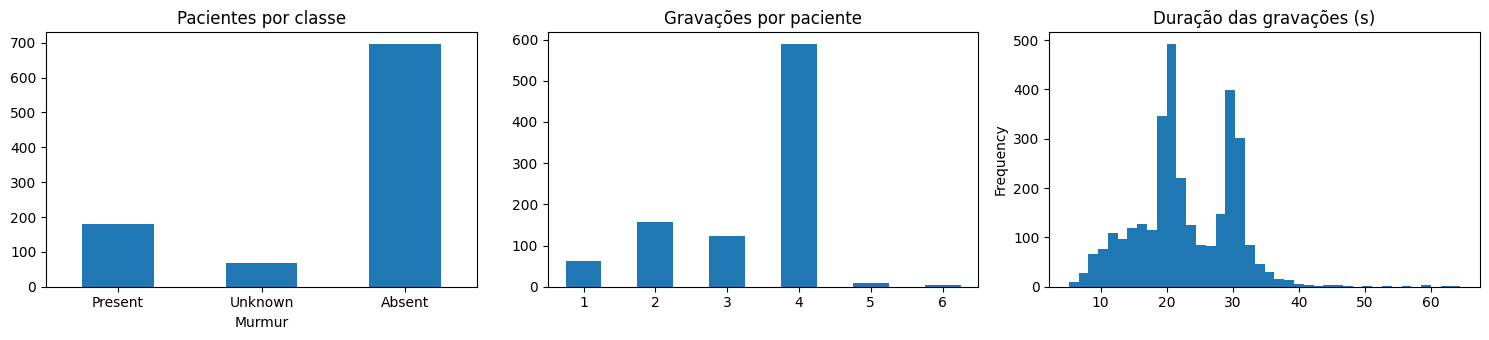

Duração (s) por classe do paciente:
          count  mean  std  min   25%   50%   75%   max
Murmur                                                 
Absent   2391.0  23.1  7.1  5.2  19.1  21.7  29.6  58.8
Present   616.0  22.3  7.9  6.4  18.2  21.0  28.6  64.5
Unknown   156.0  22.4  7.0  7.6  19.2  21.1  27.2  43.9

Gravações por foco de auscultação e classe:
Murmur  Absent  Present  Unknown
loc                             
AV         603      152       45
MV         637      172       52
PV         586      147       33
Phc          2        2        0
TV         563      143       26


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
pat["Murmur"].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], title="Pacientes por classe", rot=0)
rec.groupby("patient_id").size().value_counts().sort_index().plot.bar(ax=ax[1], title="Gravações por paciente", rot=0)
rec["dur"].plot.hist(bins=40, ax=ax[2], title="Duração das gravações (s)")
plt.tight_layout(); plt.show()

print("Duração (s) por classe do paciente:")
print(rec.groupby("Murmur")["dur"].describe().round(1))
print("\nGravações por foco de auscultação e classe:")
print(pd.crosstab(rec["loc"], rec["Murmur"]))

In [4]:
# Resumo automático da exploração (os números vêm diretamente dos dados)
cls = pat["Murmur"].value_counts()
per_pat = rec.groupby("patient_id").size()
foc = rec["loc"].value_counts()
sem_rec = set(pat.patient_id) - set(rec.patient_id)

print("Distribuição das classes (pacientes): " + ", ".join(f"{c}: {cls[c]} ({100 * cls[c] / len(pat):.1f}%)" for c in CLASSES))
print(f"Gravações: {len(rec)} de {rec.patient_id.nunique()} pacientes; por paciente, média {per_pat.mean():.1f} (mín. {per_pat.min()}, máx. {per_pat.max()})")
print(f"Duração: mediana {rec.dur.median():.1f} s (mín. {rec.dur.min():.1f} s, máx. {rec.dur.max():.1f} s); {(rec.dur < 5.0).sum()} gravações com menos de {5.0:.0f} s")
print("Gravações por foco de auscultação: " + ", ".join(f"{l}: {n}" for l, n in foc.items()))
print(f"Pacientes no CSV sem nenhum ficheiro de áudio: {len(sem_rec)}")

Distribuição das classes (pacientes): Present: 179 (19.0%), Unknown: 68 (7.2%), Absent: 695 (73.8%)
Gravações: 3163 de 942 pacientes; por paciente, média 3.4 (mín. 1, máx. 6)
Duração: mediana 21.5 s (mín. 5.2 s, máx. 64.5 s); 0 gravações com menos de 5 s
Gravações por foco de auscultação: MV: 861, AV: 800, PV: 766, TV: 732, Phc: 4
Pacientes no CSV sem nenhum ficheiro de áudio: 0


---

## 7. Protocolo de avaliação: validação cruzada por paciente

Em vez de um único split treino/validação/teste, usamos **validação cruzada com 5 folds, feita por paciente**. Em cada iteração:

| Conjunto | Pacientes | Para que serve |
|---|---|---|
| Teste | 1 fold (20% dos pacientes) | Avaliação final dessa iteração; **nunca** usado para tomar decisões |
| Validação | 15% dos restantes, escolhidos aleatoriamente | Early stopping, hiperparâmetros, escolha da agregação por paciente |
| Treino | O resto | Ajustar os pesos da rede |

**Porquê:**
- **Por paciente:** todas as gravações do mesmo paciente ficam no mesmo conjunto (obrigatório; senão os resultados ficam demasiado otimistas). Como a tabela `pat` tem uma linha por paciente, dividir essa tabela já garante isto.
- **Estratificado pela classe `Murmur`:** cada fold mantém proporções de classes semelhantes, o que é importante porque `Unknown` é muito pequena.
- **Porquê validação cruzada em vez de um split único:** com um teste de 15%, `Unknown` teria só cerca de 10 pacientes e o resultado dependeria muito de quais calharam. Na validação cruzada **todos os pacientes são testados exatamente uma vez**, por isso a matriz de confusão agregada usa todos os `Unknown` do dataset, e reportamos a média e o desvio-padrão da WA entre folds (permitido pelo enunciado).
- **Custo:** cada modelo é treinado 5 vezes. Durante o desenvolvimento e a escolha de hiperparâmetros, usamos apenas um fold (treino + validação); só no fim corremos os 5 folds.
- **Mesmos folds para MLP e CNN** (`random_state` fixo), para a comparação ser justa.
- **Normalização por fold:** as estatísticas de normalização são calculadas só com os pacientes de treino de cada fold (secção 9).

In [5]:
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.zeros(len(pat), dtype=int)
for k, (_, test_i) in enumerate(skf.split(pat, pat["Murmur"])):    # pat tem 1 linha por paciente
    folds[test_i] = k
pat["fold"] = folds
rec["fold"] = rec.patient_id.map(pat.set_index("patient_id")["fold"])

def fold_patients(k, val_size=0.15):
    """Devolve (treino, validação, teste) como conjuntos de patient_id para o fold k."""
    test_p = pat[pat.fold == k]
    rest = pat[pat.fold != k]
    tr_p, va_p = train_test_split(rest, test_size=val_size, stratify=rest["Murmur"], random_state=SEED + k)
    return set(tr_p.patient_id), set(va_p.patient_id), set(test_p.patient_id)

# verificação: sem sobreposição entre conjuntos, em todos os folds
for k in range(N_FOLDS):
    a, b, c = fold_patients(k)
    assert not (a & b) and not (a & c) and not (b & c)

print("Pacientes por fold (teste) e classe:")
print(pd.crosstab(pat["fold"], pat["Murmur"])[CLASSES])

Pacientes por fold (teste) e classe:
Murmur  Present  Unknown  Absent
fold                            
0            36       14     139
1            36       14     139
2            36       13     139
3            36       13     139
4            35       14     139


---

## 8. Pré-processamento comum (sinal → janelas)

Este passo é igual para a MLP e para a CNN. Parte do ficheiro `.wav` e produz **janelas de áudio com tamanho fixo**, limpas e normalizadas.

| Passo | Valor | Justificação |
|---|---|---|
| Frequência de amostragem | 4000 Hz | É a frequência original das gravações, logo não se perde informação. O código reamostra apenas se algum ficheiro for diferente. |
| Filtro passa-banda | 25–600 Hz (Butterworth, ordem 4, sem desfasamento) | Os sons cardíacos e os sopros têm a energia concentrada em baixas frequências. Abaixo de ~25 Hz há sobretudo ruído de movimento e, acima de ~600 Hz, ruído ambiente. |
| Normalização | z-score por gravação | Os níveis de amplitude variam entre gravações (pressão do estetoscópio, ganho); assim o modelo foca-se na forma do sinal e não no volume. |
| Janela | 5 s | Um ciclo cardíaco dura cerca de 0,5–1 s, por isso 5 s contêm vários ciclos (informação suficiente para detetar um sopro). A gravação mais curta tem 4,8 s, logo quase não é preciso padding. |
| Passo (hop) | 2,5 s (50% de sobreposição) | Dá mais janelas por gravação, o que aumenta o número de exemplos sem alterar os dados. |
| Gravações < 5 s | padding com zeros | Mantém todas as janelas com o mesmo tamanho. |

valores a ser ajustados com base nos resultados na validaçao (nao no teste)

In [6]:
FS = 4000                                  # frequência de amostragem alvo (Hz)
WIN_S, HOP_S = 5.0, 2.5                    # janela e passo (s)
WIN, HOP = int(WIN_S * FS), int(HOP_S * FS)
LOW, HIGH = 25, 600                        # banda do filtro (Hz)
SOS = butter(4, [LOW, HIGH], btype="band", fs=FS, output="sos")

def load_clean(path):
    """Lê o .wav, reamostra se necessário, filtra e normaliza."""
    x, fs = sf.read(path, dtype="float32")
    if fs != FS:
        x = librosa.resample(x, orig_sr=fs, target_sr=FS)
    x = sosfiltfilt(SOS, x)                # passa-banda sem desfasamento
    x = x - x.mean()
    x = x / (x.std() + 1e-8)               # z-score por gravação
    return x.astype(np.float32)

def windows(x):
    """Divide o sinal em janelas de WIN amostras (com sobreposição); padding se for mais curto."""
    if len(x) < WIN:
        x = np.pad(x, (0, WIN - len(x)))
    return [x[s:s + WIN] for s in range(0, len(x) - WIN + 1, HOP)]

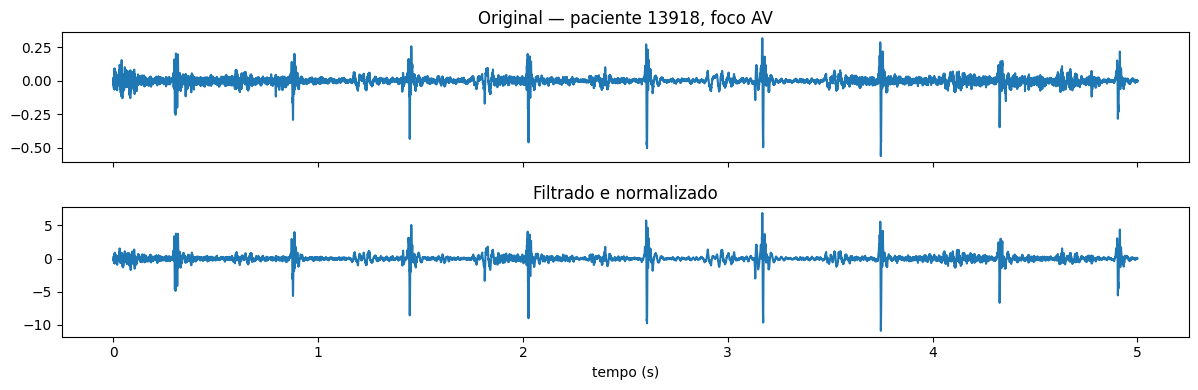

Número aproximado de janelas no dataset: 24198


In [7]:
# Efeito do pré-processamento numa gravação (resultado intermédio para os slides)
r = rec.iloc[0]
x_raw, _ = sf.read(r.path, dtype="float32")
x_cl = load_clean(r.path)
t = np.arange(int(5 * FS)) / FS
fig, ax = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
ax[0].plot(t, x_raw[:len(t)]);  ax[0].set_title(f"Original — paciente {r.patient_id}, foco {r['loc']}")
ax[1].plot(t, x_cl[:len(t)]);   ax[1].set_title("Filtrado e normalizado")
ax[1].set_xlabel("tempo (s)"); plt.tight_layout(); plt.show()

n_win = rec.dur.apply(lambda d: max(1, int((d * FS - WIN) // HOP) + 1)).sum()
print(f"Número aproximado de janelas no dataset: {n_win}")

---

## 9. Representações de entrada para cada modelo

Uma janela de 5 s a 4000 Hz tem 20 000 valores de amplitude. A **representação** é a forma como transformamos esses 20 000 valores no que cada rede recebe à entrada. É aqui que o pré-processamento passa a ser **diferente** para cada modelo:

**MLP — vetor de características (32 valores por janela).** A MLP só aceita um vetor de tamanho fixo e não tem noção de tempo ou de vizinhança. Por isso, resumimos cada janela em estatísticas:
- 13 coeficientes **MFCC**, que descrevem a forma do espectro;
- **centróide espectral** (onde está o "centro" da energia em frequência);
- **energia RMS** (intensidade);
- **taxa de passagem por zero** (indicador do carácter mais "ruidoso" ou "tonal" do sinal).

Cada uma destas 16 séries temporais é resumida pela **média** e pelo **desvio-padrão** ao longo da janela, dando 16 × 2 = 32 valores.

**CNN 2D — espectrograma Mel (32 × 157 por janela).** É uma "imagem" com a frequência no eixo vertical (32 bandas Mel) e o tempo no horizontal (157 instantes), onde cada ponto é a energia (em dB) nessa banda e nesse instante. A CNN usa convoluções para aprender padrões locais (por exemplo, um sopro entre S1 e S2 aparece como energia contínua em certas bandas).

**Parâmetros do espectrograma:** `n_fft=512` (janelas de 128 ms, resolução de ~8 Hz) e `hop=128` (um instante a cada 32 ms) dão um compromisso razoável entre resolução temporal e em frequência para sons de baixa frequência; 32 bandas Mel cobrem a banda 25–600 Hz. As MFCC são calculadas com os mesmos parâmetros.

**Normalização:** as estatísticas (média e desvio-padrão) são calculadas **só nos pacientes de treino de cada fold** e aplicadas aos três conjuntos desse fold. Se incluíssemos validação ou teste, haveria fuga de informação.

**Labels:** cada janela herda a label do **paciente**. Mais tarde, as previsões das janelas serão combinadas para dar uma previsão por paciente (secção 10).

In [8]:
N_FFT, HOP_L, N_MELS = 512, 128, 32

def mel_spec(w):
    """Espectrograma Mel em dB, forma (N_MELS, T)."""
    S = librosa.feature.melspectrogram(y=w, sr=FS, n_fft=N_FFT, hop_length=HOP_L,
                                       n_mels=N_MELS, fmin=LOW, fmax=HIGH)
    return librosa.power_to_db(S, ref=1.0, top_db=80).astype(np.float16)

def mlp_features(w):
    """Vetor de 32 características (média e desvio-padrão de 16 séries)."""
    mfcc = librosa.feature.mfcc(y=w, sr=FS, n_mfcc=13, n_fft=N_FFT, hop_length=HOP_L,
                                n_mels=N_MELS, fmin=LOW, fmax=HIGH)
    cent = librosa.feature.spectral_centroid(y=w, sr=FS, n_fft=N_FFT, hop_length=HOP_L)
    rms  = librosa.feature.rms(y=w, frame_length=N_FFT, hop_length=HOP_L)
    zcr  = librosa.feature.zero_crossing_rate(w, frame_length=N_FFT, hop_length=HOP_L)
    F = np.vstack([mfcc, cent, rms, zcr])                      # (16, T)
    return np.concatenate([F.mean(1), F.std(1)]).astype(np.float32)

def build_split(rec_df):
    """Para cada gravação -> janelas -> (features MLP, espectrograma CNN, metadados)."""
    Xf, Xs, idx = [], [], []
    for r in rec_df.itertuples():
        for k, w in enumerate(windows(load_clean(r.path))):
            Xf.append(mlp_features(w)); Xs.append(mel_spec(w))
            idx.append((r.patient_id, r.loc, k))
    idx = pd.DataFrame(idx, columns=["patient_id", "loc", "win"])
    idx["y"] = idx.patient_id.map(pat.set_index("patient_id")["Murmur"])
    return np.stack(Xf), np.stack(Xs), idx

In [9]:
# As janelas e as features não dependem do fold (não há nada "ajustado" aos dados), por isso calculam-se uma só vez
# para todos os pacientes. O cálculo demora; o resultado fica em cache. Se mudarem algum parâmetro acima, a cache é recalculada.
tag = f"{FS}_{WIN_S}_{HOP_S}_{LOW}_{HIGH}_{N_FFT}_{HOP_L}_{N_MELS}"
CACHE = f"cache_features_{tag}.pkl"

if os.path.exists(CACHE):
    data_all = pickle.load(open(CACHE, "rb"))
    print("Cache carregada:", CACHE)
else:
    data_all = build_split(rec)
    pickle.dump(data_all, open(CACHE, "wb"))

Xf_all, Xs_all, idx_all = data_all
print(f"MLP: {Xf_all.shape}  CNN: {Xs_all.shape}")
print("Janelas por classe:", idx_all.y.value_counts().to_dict())

MLP: (24198, 32)  CNN: (24198, 32, 157)
Janelas por classe: {'Absent': 18463, 'Present': 4574, 'Unknown': 1161}


In [10]:
def make_fold(k, val_size=0.15):
    """Dados do fold k, normalizados com estatísticas calculadas APENAS nos pacientes de treino desse fold."""
    tr_p, va_p, te_p = fold_patients(k, val_size)
    masks = {"train": idx_all.patient_id.isin(tr_p).values,
             "val":   idx_all.patient_id.isin(va_p).values,
             "test":  idx_all.patient_id.isin(te_p).values}

    scaler = StandardScaler().fit(Xf_all[masks["train"]])                      # MLP
    Xs_train = Xs_all[masks["train"]].astype(np.float32)
    mu, sd = Xs_train.mean(), Xs_train.std()                                  # CNN

    out = {}
    for s, m in masks.items():
        out[s] = dict(
            X_mlp=scaler.transform(Xf_all[m]).astype(np.float32),                          # (N, 32)
            X_cnn=((Xs_all[m].astype(np.float32) - mu) / sd)[:, None],                      # (N, 1, 32, T)
            meta=idx_all[m].reset_index(drop=True))                                         # patient_id, loc, win, y
    return out

fold0 = make_fold(0)   # exemplo: fold usado durante o desenvolvimento
for s, d in fold0.items():
    print(f"{s:5s} MLP: {d['X_mlp'].shape}  CNN: {d['X_cnn'].shape}  pacientes: {d['meta'].patient_id.nunique()}  janelas por classe: {d['meta'].y.value_counts().to_dict()}")

train MLP: (16411, 32)  CNN: (16411, 1, 32, 157)  pacientes: 640  janelas por classe: {'Absent': 12619, 'Present': 3067, 'Unknown': 725}
val   MLP: (2787, 32)  CNN: (2787, 1, 32, 157)  pacientes: 113  janelas por classe: {'Absent': 2070, 'Present': 586, 'Unknown': 131}
test  MLP: (5000, 32)  CNN: (5000, 1, 32, 157)  pacientes: 189  janelas por classe: {'Absent': 3774, 'Present': 921, 'Unknown': 305}


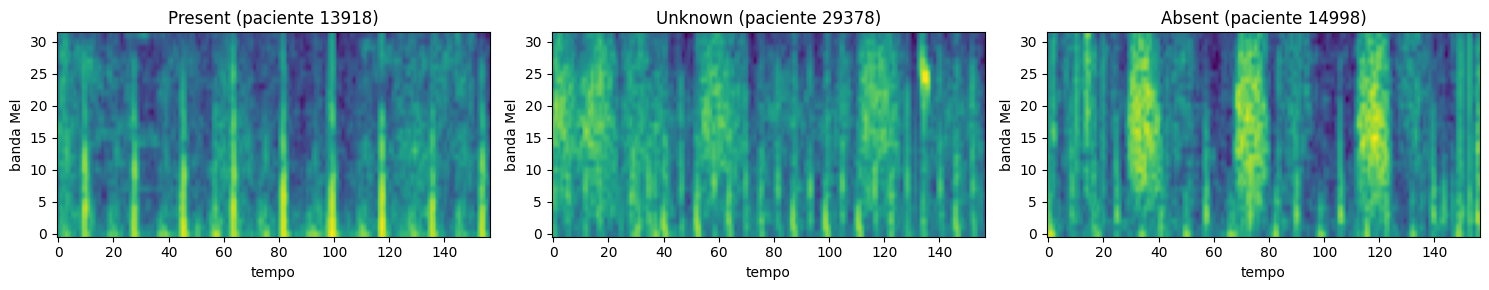

In [11]:
# Verificação visual: um espectrograma de cada classe
fig, ax = plt.subplots(1, 3, figsize=(15, 3))
idx_tr = idx_all
for a, c in zip(ax, CLASSES):
    i = idx_tr.index[idx_tr.y == c][0]
    a.imshow(Xs_all[i].astype(np.float32), origin="lower", aspect="auto")
    a.set_title(f"{c} (paciente {idx_tr.patient_id[i]})"); a.set_xlabel("tempo"); a.set_ylabel("banda Mel")
plt.tight_layout(); plt.show()

---

## 10. Métrica e previsão por paciente

O enunciado exige **uma previsão por paciente** e avalia com a *weighted accuracy* (WA_murmur): é a accuracy em que cada paciente `Present` conta 5 vezes, cada `Unknown` 3 vezes e cada `Absent` 1 vez.

Como a rede classifica **janelas**, é preciso combinar as previsões de todas as janelas (de todas as gravações) de um paciente numa só. O ponto de partida é a **média das probabilidades** das janelas; esta escolha pode ser comparada com outras (voto maioritário, máximo) na validação e justificada nos slides.

No fim, `summarize_cv` junta os resultados dos 5 folds: WA média ± desvio-padrão e matriz de confusão agregada (com todos os pacientes).

In [12]:
from sklearn.metrics import confusion_matrix

W = {"Present": 5, "Unknown": 3, "Absent": 1}

def weighted_accuracy(y_true, y_pred):
    """WA_murmur: accuracy com pesos 5/3/1 por classe verdadeira (ao nível do paciente)."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    w = np.array([W[t] for t in y_true])
    return (w * (y_true == y_pred)).sum() / w.sum()

def patient_predictions(idx, probs):
    """probs: (N_janelas, 3), colunas na ordem CLASSES. Devolve 1 previsão por paciente (média das probabilidades)."""
    df = pd.DataFrame(probs, columns=CLASSES)
    df["patient_id"] = idx.patient_id.values
    return df.groupby("patient_id")[CLASSES].mean().idxmax(axis=1)

def patient_confusion(y_true, y_pred):
    """Matriz com linhas = previsto e colunas = verdadeiro, como na Tabela 1 do enunciado."""
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=CLASSES).T,
                        index=[f"pred {c}" for c in CLASSES], columns=[f"true {c}" for c in CLASSES])

def summarize_cv(fold_results):
    """fold_results: lista com um (y_true, y_pred) por fold, ao nível do paciente.
    Reporta WA média ± desvio-padrão entre folds e a matriz de confusão agregada de todos os folds."""
    was = [weighted_accuracy(t, p) for t, p in fold_results]
    yt = np.concatenate([np.asarray(t) for t, _ in fold_results])
    yp = np.concatenate([np.asarray(p) for _, p in fold_results])
    print(f"WA_murmur por fold: {np.round(was, 3)}")
    print(f"WA_murmur: {np.mean(was):.3f} ± {np.std(was):.3f}   (agregado: {weighted_accuracy(yt, yp):.3f})")
    print("\nMatriz de confusão agregada (linhas = previsto, colunas = verdadeiro):")
    print(patient_confusion(yt, yp))

# Referência: um classificador que prevê sempre "Absent" (WA baixo apesar de accuracy alta)
y_all = pat["Murmur"].values
print("WA — baseline 'sempre Absent':", round(weighted_accuracy(y_all, ["Absent"] * len(y_all)), 3))

WA — baseline 'sempre Absent': 0.387
